**Future Sales Prediction Project**

**Member-Name : Fasi-Uddin Sajjad**

**Member-Name : Ghulam Mustafa**


**Objective : The goal is to predict future Sales based on past data.**

In [92]:
#Importing the Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [93]:
data = pd.read_csv("Sales Pro.csv",index_col = 0)

In [94]:
data

,Product,Company,Category,Units Sold,Revenue,Cost of Goods Sold,Profit,Purchase Date,Customer Name,Customer State,Customer City,Customer Zip Code,Order ID
0,Coffee,Coca-Cola,Coffee,151,2141,4956,-2815,2020-07-04,Angela Wilson,California,East Danielleview,35273,1-143-51064-X
1,Coffee,Coca-Cola,Coffee,624,1620,1156,464,2021-04-09,Zachary Wheeler,Wisconsin,New Kimberlyshire,55509,1-163-25655-2
2,Wine,Coca-Cola,Alcoholic,853,9978,1030,8948,2022-03-10,Jeremy Arroyo,Massachusetts,Vickieshire,93236,0-345-30366-0
3,Green Tea,Dr. Pepper,Tea,962,5974,5279,695,2023-05-10,Andrew Fleming,Arizona,Albertberg,34895,1-4844-8219-0
4,Vodka,Dr. Pepper,Alcoholic,719,3928,2828,1100,2020-11-19,Caroline Smith,Indiana,Johnsonstad,90201,1-85816-387-0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,Herbal Tea,Coca-Cola,Tea,859,4143,5689,-1546,2022-04-30,Latoya Bruce,Texas,Katieton,35239,0-18-108008-7
1996,Vodka,Pepsi,Alcoholic,183,9624,695,8929,2020-06-16,Jose Montoya,Florida,Rossfort,89407,0-8070-0411-1
1997,Cola,Pepsi,Soft Drink,713,7238,5787,1451,2021-11-08,Ronald Smith,Alaska,Melissaburgh,22037,0-7374-9116-7
1998,Black Tea,Coca-Cola,Tea,601,2873,5217,-2344,2022-02-20,Brenda Decker,West Virginia,Loweberg,61431,1-992588-37-6


In [95]:
data = data.drop("Units Sold",axis=1)
data

,Product,Company,Category,Revenue,Cost of Goods Sold,Profit,Purchase Date,Customer Name,Customer State,Customer City,Customer Zip Code,Order ID
0,Coffee,Coca-Cola,Coffee,2141,4956,-2815,2020-07-04,Angela Wilson,California,East Danielleview,35273,1-143-51064-X
1,Coffee,Coca-Cola,Coffee,1620,1156,464,2021-04-09,Zachary Wheeler,Wisconsin,New Kimberlyshire,55509,1-163-25655-2
2,Wine,Coca-Cola,Alcoholic,9978,1030,8948,2022-03-10,Jeremy Arroyo,Massachusetts,Vickieshire,93236,0-345-30366-0
3,Green Tea,Dr. Pepper,Tea,5974,5279,695,2023-05-10,Andrew Fleming,Arizona,Albertberg,34895,1-4844-8219-0
4,Vodka,Dr. Pepper,Alcoholic,3928,2828,1100,2020-11-19,Caroline Smith,Indiana,Johnsonstad,90201,1-85816-387-0
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,Herbal Tea,Coca-Cola,Tea,4143,5689,-1546,2022-04-30,Latoya Bruce,Texas,Katieton,35239,0-18-108008-7
1996,Vodka,Pepsi,Alcoholic,9624,695,8929,2020-06-16,Jose Montoya,Florida,Rossfort,89407,0-8070-0411-1
1997,Cola,Pepsi,Soft Drink,7238,5787,1451,2021-11-08,Ronald Smith,Alaska,Melissaburgh,22037,0-7374-9116-7
1998,Black Tea,Coca-Cola,Tea,2873,5217,-2344,2022-02-20,Brenda Decker,West Virginia,Loweberg,61431,1-992588-37-6


In [96]:
data.rename(columns ={'Revenue':'Sales'},inplace = True)

In [97]:
data.head()

,Product,Company,Category,Sales,Cost of Goods Sold,Profit,Purchase Date,Customer Name,Customer State,Customer City,Customer Zip Code,Order ID
0,Coffee,Coca-Cola,Coffee,2141,4956,-2815,2020-07-04,Angela Wilson,California,East Danielleview,35273,1-143-51064-X
1,Coffee,Coca-Cola,Coffee,1620,1156,464,2021-04-09,Zachary Wheeler,Wisconsin,New Kimberlyshire,55509,1-163-25655-2
2,Wine,Coca-Cola,Alcoholic,9978,1030,8948,2022-03-10,Jeremy Arroyo,Massachusetts,Vickieshire,93236,0-345-30366-0
3,Green Tea,Dr. Pepper,Tea,5974,5279,695,2023-05-10,Andrew Fleming,Arizona,Albertberg,34895,1-4844-8219-0
4,Vodka,Dr. Pepper,Alcoholic,3928,2828,1100,2020-11-19,Caroline Smith,Indiana,Johnsonstad,90201,1-85816-387-0


In [98]:
data.tail()

,Product,Company,Category,Sales,Cost of Goods Sold,Profit,Purchase Date,Customer Name,Customer State,Customer City,Customer Zip Code,Order ID
1995,Herbal Tea,Coca-Cola,Tea,4143,5689,-1546,2022-04-30,Latoya Bruce,Texas,Katieton,35239,0-18-108008-7
1996,Vodka,Pepsi,Alcoholic,9624,695,8929,2020-06-16,Jose Montoya,Florida,Rossfort,89407,0-8070-0411-1
1997,Cola,Pepsi,Soft Drink,7238,5787,1451,2021-11-08,Ronald Smith,Alaska,Melissaburgh,22037,0-7374-9116-7
1998,Black Tea,Coca-Cola,Tea,2873,5217,-2344,2022-02-20,Brenda Decker,West Virginia,Loweberg,61431,1-992588-37-6
1999,Green Tea,Dr. Pepper,Tea,1706,2648,-942,2023-07-10,Aaron Flowers,Nebraska,New Jamesfort,84559,0-14-955998-4


In [99]:
from sklearn.ensemble import RandomForestRegressor
# Convert date
data['Purchase Date'] = pd.to_datetime(data['Purchase Date'])

# Extract features
data['Day'] = data['Purchase Date'].dt.day
data['Month'] = data['Purchase Date'].dt.month
data['Year'] = data['Purchase Date'].dt.year
data['DayOfWeek'] = data['Purchase Date'].dt.dayofweek

data = data.sort_values('Purchase Date')

data['lag_1'] = data['Sales'].shift(1)
data['lag_7'] = data['Sales'].shift(7)
data['lag_3'] = data['Sales'].shift(3)
data['lag_14'] = data['Sales'].shift(14)

data = data.dropna()

data['Month_sin'] = np.sin(2 * np.pi * data['Month']/12)
data['Month_cos'] = np.cos(2 * np.pi * data['Month']/12)

data['DayOfWeek_sin'] = np.sin(2 * np.pi * data['DayOfWeek']/7)
data['DayOfWeek_cos'] = np.cos(2 * np.pi * data['DayOfWeek']/7)



data['rolling_mean_7'] = data['Sales'].rolling(window=7).mean()
data['rolling_mean_3'] = data['Sales'].rolling(3).mean()
data['rolling_mean_14'] = data['Sales'].rolling(14).mean()

data['rolling_std_7'] = data['Sales'].rolling(7).std()

data['trend'] = data['Sales'].diff()


# Define X BEFORE encoding
X = data[['trend','Product','Company','Category','Day','Month','Year','DayOfWeek','lag_1','lag_7','lag_3','lag_14','rolling_mean_7','rolling_mean_3','Month_sin','Month_cos',
          'DayOfWeek_sin','DayOfWeek_cos','rolling_mean_14','rolling_std_7']]
y = data['Sales']

# Apply One-Hot Encoding (DO NOT overwrite later)
X = pd.get_dummies(X, columns=['Product','Company','Category'])

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Improved Decision Tree (control overfitting)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')
print(f'R2 Score: {r2}')

MAE: 243.24
MSE: 98010.45
R2 Score: 0.9862336504750727


In [100]:
# Predictions on test set
y_pred = model.predict(X_test)

# Show sample results
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(results.head(4))

   Actual  Predicted
0    7281    6877.94
1    2261    2095.39
2    7924    8317.10
3    7759    8485.73


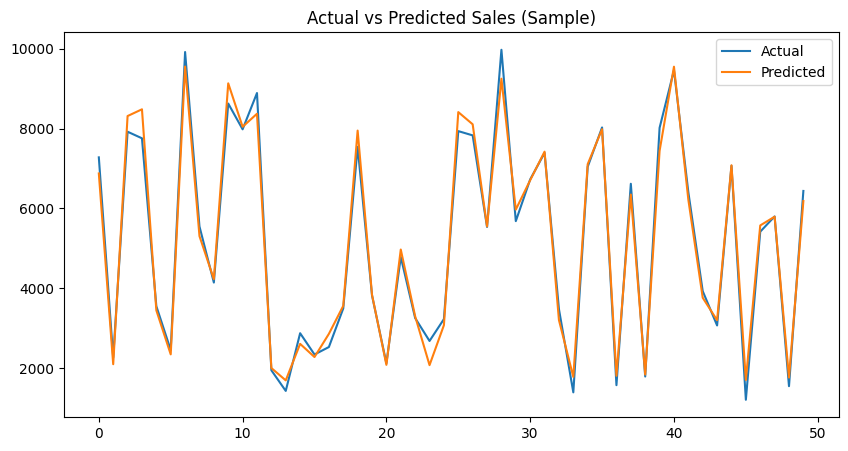

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(y_test.values[:50], label='Actual')
plt.plot(y_pred[:50], label='Predicted')
plt.legend()
plt.title("Actual vs Predicted Sales (Sample)")
plt.show()